(sec:modal_fine_macm)=
# Modal Fixture Neutralization and the Modal Amplitude Contribution Map

This example demonstrates the **Modal FINE** (Fixture Neutralization) technique and the
**Modal Amplitude Contribution Map (MACM)** from {cite}`zwink2020_dynamic_response_matching_dissertation`,
restated in {cite}`matthews2026_modal_fine_macm`,
implemented in `sdynpy.modal.sdynpy_macm`.

Modal FINE computes a laboratory excitation force that causes a Device Under Test (DUT) to
respond the same way in a laboratory boundary condition ("DL2") as it did in a field boundary
condition ("DL1"), using only the mode shapes/frequencies/damping of the two assemblies. This is
a companion technique to Impedance FINE {cite}`skousen2026_impedance_fine`, which instead works
directly with connection-DOF FRFs; Modal FINE works in modal coordinates, and its Modal Amplitude
Contribution Map (MACM) reveals *which laboratory modes are actually needed* to reconstruct
each field mode's contribution to the target response -- a diagnostic for judging whether a
chosen set of laboratory shaker locations is well- or poorly-conditioned before ever running a
test.

## Theory, briefly

For a DUT attached to a field fixture (assembly "DL1") and, separately, to a laboratory fixture
(assembly "DL2"), Modal FINE seeks a laboratory force $\{F_j^{(DL2)}\}$ at candidate force DOFs
"j" that reproduces the DUT response $\{X_i^{(DL1)}\}$ at target DOFs "i":

$$
\{X_i^{(DL2)}\} = [H_{ij}^{(DL2)}]\{F_j^{(DL2)}\}
\qquad\Longrightarrow\qquad
\{F_j^{(DL2)}\} = [H_{ij}^{(DL2)}]^{g}\{X_i^{(DL1)}\}
$$

where $[\cdot]^g$ is the Moore-Penrose pseudo-inverse. Directly computing this gives no insight
into *why* one choice of force DOFs works better than another. The MACM re-expresses this same
calculation in modal coordinates, decomposing it mode-by-mode so that a poorly-conditioned DOF
choice shows up as a contribution smeared across many laboratory modes, rather than concentrated
in a few.

```{note}
Zwink's dissertation {cite}`zwink2020_dynamic_response_matching_dissertation` consistently calls this the Modal Amplitude Contribution *Map*. Matthews et al. (2026) introduces it once as the Modal Amplitude Contribution *Matrix*, then uses "Map" for the rest of the paper (including a section heading), matching the dissertation. This notebook and `sdynpy_macm` follow the dissertation's original, consistently-used name; the abbreviation "MACM" is unaffected either way.
```

```{note}
The paper's printed Eqs. 8, 10, and 11 have a typo: the synthesized-FRF term inside them uses the
response-DOF mode shape matrix $U_i$ in every slot, where the force-DOF slots should use $U_j$
(consistent with Eq. 7, which Eq. 8 is derived from). `sdynpy_macm` implements the corrected
general form; see the module docstring for the full derivation and the `tests/macm_test.py`
suite for the numerical verification against an independent reference calculation.
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import sdynpy as sdpy
from sdynpy.demo.two_beam_modal_fine import create_case_1_models, in_plane_shapes, sine_burst_force
from sdynpy.modal.sdynpy_macm import (
    compute_modal_fine,
    modal_transformation_matrix,
    modal_amplitude_contribution_map,
    modal_response_from_force,
    effective_mode_count,
    plot_macm,
)

## The two-beam test case

We use the "Case 1" analytical model from {cite}`matthews2026_modal_fine_macm` (Appendix A.6/A.7):
a Device Under Test (DUT) beam attached to a fixture beam. In the field configuration the DUT is
centered on the fixture; in the laboratory configuration it is shifted 12 inches to the right,
producing a different dynamic boundary condition for the same DUT.

In [2]:
models = create_case_1_models()
print('Field connection nodes (on the fixture):', models['field_connection_nodes'])
print('Lab connection nodes   (on the fixture):', models['lab_connection_nodes'])

Field connection nodes (on the fixture): (26, 114)
Lab connection nodes   (on the fixture): (38, 126)


`beamkm` builds a full 3D beam element (6 DOF/node), but the paper's model is effectively
planar. `in_plane_shapes` filters an eigensolution down to the modes dominated by the
Z-translation/Y-rotation bending behavior the paper's model represents, discarding the
out-of-plane modes that have no counterpart in the paper.

In [3]:
field_shapes = in_plane_shapes(models['field'], 300)
lab_shapes = in_plane_shapes(models['lab'], 300)

# A small amount of uniform modal damping is needed to evaluate FRFs near
# resonance (the natural-frequency comparison against the paper's Table 1
# uses the undamped system; damping doesn't change natural frequencies).
field_shapes.damping = 0.01
lab_shapes.damping = 0.01

print(f'{field_shapes.shape[0]} in-plane field modes, '
      f'{lab_shapes.shape[0]} in-plane lab modes')
print('First 4 field natural frequencies (Hz):', np.round(field_shapes.frequency[:4], 2))
print('  (paper Table 1, field, first 4 modes: 7.8, 10.2, 22.7, 30.1 Hz)')

82 in-plane field modes, 82 in-plane lab modes
First 4 field natural frequencies (Hz): [ 7.8  10.15 22.65 30.1 ]
  (paper Table 1, field, first 4 modes: 7.8, 10.2, 22.7, 30.1 Hz)


## Good vs. poor laboratory force locations

Following the paper's Case 1.1/1.2 comparison, we drive the field assembly at its 4th mode
(~30 Hz) and ask: what laboratory force reproduces this response, using either a set of forces
spread out across the fixture ("good") or clustered close together on 3 adjacent nodes ("poor")?
Both choices use 3 force DOFs and 3 response DOFs, so both are square, generically invertible
problems -- the paper's point is that *both* can reproduce the target almost exactly, but at very
different practical cost.

In [4]:
response_dofs = sdpy.coordinate_array(node=[1000 + n for n in (10, 50, 90)], direction=3)
field_excitation_dof = sdpy.coordinate_array(node=[2000 + 136], direction=3)
good_force_dofs = sdpy.coordinate_array(node=[2000 + n for n in (6, 70, 134)], direction=3)
poor_force_dofs = sdpy.coordinate_array(node=[2000 + n for n in (69, 70, 71)], direction=3)

field_mode_index = 3  # the paper's "field mode 4"
field_mode_freq = field_shapes.frequency[field_mode_index]
frequencies = np.linspace(field_mode_freq - 5, field_mode_freq + 5, 11)
frequencies = frequencies[frequencies > 0.1]
freq_index = np.argmin(np.abs(frequencies - field_mode_freq))

target_response = field_shapes.compute_frf(
    frequencies, responses=response_dofs, references=field_excitation_dof).ordinate[:, 0, :]
print(f'Driving field assembly near mode {field_mode_index + 1} ({field_mode_freq:.2f} Hz)')

Driving field assembly near mode 4 (30.10 Hz)


In [5]:
results = {}
for label, force_dofs in [('good', good_force_dofs), ('poor', poor_force_dofs)]:
    result = compute_modal_fine(field_shapes, lab_shapes, response_dofs, force_dofs,
                                target_response, frequencies)
    lab_frf = lab_shapes.compute_frf(frequencies, responses=response_dofs,
                                     references=force_dofs).ordinate
    reconstructed = np.einsum('ijw,jw->iw', lab_frf, result.lab_forces)
    results[label] = dict(result=result, reconstructed=reconstructed)
    print(f"{label:>5s} placement: max|force| = {np.max(np.abs(result.lab_forces)):10.3g} lbf   "
          f"max|response error| = {np.max(np.abs(reconstructed - target_response)):.2e}")

 good placement: max|force| =       5.49 lbf   max|response error| = 3.14e-12
 poor placement: max|force| =   1.14e+05 lbf   max|response error| = 2.49e-08


Both placements reproduce the target response almost exactly (the max response error is
many orders of magnitude below the response itself) -- but the poor placement's forces are
dramatically larger, echoing the paper's finding that a poorly-conditioned placement "may be
unrealizable in a physical system with actual shakers."</p>

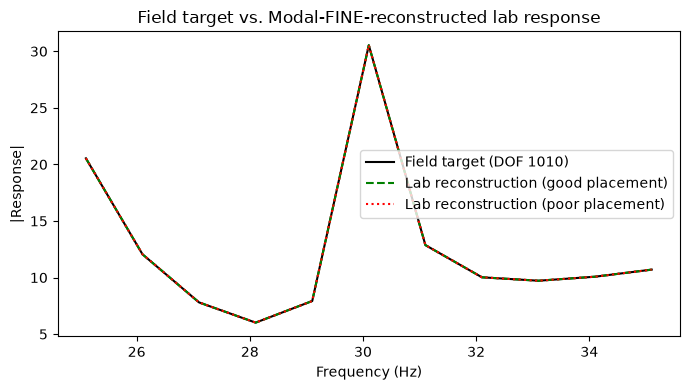

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(frequencies, np.abs(target_response[0]), 'k-', label='Field target (DOF 1010)')
for label, style in [('good', 'g--'), ('poor', 'r:')]:
    ax.plot(frequencies, np.abs(results[label]['reconstructed'][0]), style,
           label=f'Lab reconstruction ({label} placement)')
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('|Response|')
ax.legend()
ax.set_title('Field target vs. Modal-FINE-reconstructed lab response')
fig.tight_layout()

## The MACM: why the poor placement needs such large forces

The MACM decomposes the laboratory modal response into the contribution from each field mode.
Rather than idealizing the excitation as a single, perfectly isolated field mode, we generate the
actual excitation used in the paper's Case 1.1/1.2 demonstration: a Hann-windowed sine burst at
field mode 4's natural frequency, per Zwink's dissertation MATLAB (`generate_excitation_sine.m`),
Fourier-transformed and expanded directly into field modal coordinates via
`modal_response_from_force` -- the forward analog of the DOF-limited, lossy `project_modal_response`
used internally by `compute_modal_fine` above. This direction needs no pseudo-inverse at all, since
the force enters linearly through the (known) force-DOF mode shapes.

A windowed burst (rather than an idealized continuous tone) has spectral content spread over a
nonzero bandwidth around its nominal frequency, so this naturally puts some real energy into field
modes *near* mode 4 too -- matching the paper's own Figs. 12/13, which likewise show contribution
from more than one field mode, not a single isolated line.

In [7]:
macm_frequencies, force_spectrum_full = sine_burst_force(field_mode_freq)
freq_window = (macm_frequencies > field_mode_freq - 5) & (macm_frequencies < field_mode_freq + 5)
macm_frequencies = macm_frequencies[freq_window]
force_spectrum = force_spectrum_full[freq_window][np.newaxis, :]
macm_freq_index = np.argmin(np.abs(macm_frequencies - field_mode_freq))

field_modal_response = modal_response_from_force(
    field_shapes, field_excitation_dof, force_spectrum, macm_frequencies)

macm = {}
for label, force_dofs in [('good', good_force_dofs), ('poor', poor_force_dofs)]:
    transformation = modal_transformation_matrix(field_shapes, lab_shapes, response_dofs,
                                                 force_dofs, macm_frequencies)
    macm[label] = modal_amplitude_contribution_map(transformation, field_modal_response)

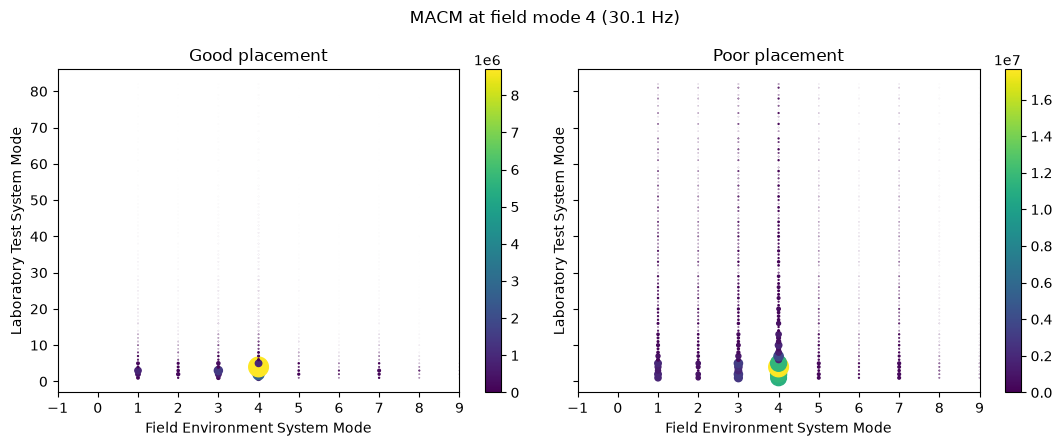

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, label in zip(axes, ('good', 'poor')):
    plot_macm(macm[label], field_shapes.frequency, lab_shapes.frequency,
             frequency_index=macm_freq_index, ax=ax)
    ax.set_title(f'{label.capitalize()} placement')
    ax.set_xlim(field_mode_index - 4, field_mode_index + 6)  # plot_macm uses 1-indexed mode numbers
fig.suptitle(f'MACM at field mode {field_mode_index + 1} ({field_mode_freq:.1f} Hz)')
fig.tight_layout()

In [9]:
for label in ('good', 'poor'):
    macm_slice = macm[label][:, field_mode_index, macm_freq_index]
    count = effective_mode_count(macm_slice, threshold=0.95)
    print(f'{label:>5s} placement needs {count} laboratory modes to reach 95% of the '
          f'field mode {field_mode_index + 1} contribution '
          f'(out of {lab_shapes.shape[0]} available)')

 good placement needs 5 laboratory modes to reach 95% of the field mode 4 contribution (out of 82 available)
 poor placement needs 16 laboratory modes to reach 95% of the field mode 4 contribution (out of 82 available)


The good placement concentrates the field mode's contribution in a handful of nearby
laboratory modes, while the poor placement smears it across noticeably more -- directly visible
in the plot, and quantified by `effective_mode_count`.

## Summary

- Both the "good" (spread out) and "poor" (clustered) laboratory force placements reproduce the
  target field response almost exactly -- Modal FINE's force calculation (Eq. 3) is exact
  regardless of DOF placement quality, given enough independent force DOFs.
- The *practical* cost of a poor placement shows up as (a) dramatically larger required forces
  and (b) a MACM spread across far more laboratory modes than a well-conditioned placement needs
  -- both directly observable *before* running a physical test, which is the whole point of
  building the MACM.
- See `tests/macm_test.py` for the full validation suite (a synthetic hand-computable check of
  the underlying tensor math, plus these Case 1 integration checks and a Case 3 broadband
  reconstruction check against a 10x fixture stiffness mismatch).